# Legal Paragraph Shorthand Image Dataset Generator

Creates **paragraph-level** shorthand images — **each image = all 5 sentences of one legal principle stacked as rows**.

- **15 principles × 1 paragraph image each = 15 paragraph images**
- Full **stroke-level preprocessing** on every symbol before stitching:
  - Otsu binarize → contour extraction → stroke count & density check → quality gate
  - Only symbols with valid, readable strokes are used
- Each sentence row is drawn separately and stacked vertically with a line gap

Runtime: GPU

---
## Step 1: Setup & Download

In [ ]:
!pip install kaggle -q

import os, cv2, csv, random, json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

os.makedirs('data/raw', exist_ok=True)
os.makedirs('output/paragraphs/images', exist_ok=True)
print('Ready')

Ready


In [ ]:
from google.colab import files
print('Upload kaggle.json:')
uploaded = files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ 2>/dev/null; chmod 600 ~/.kaggle/kaggle.json

Upload kaggle.json:


Saving kaggle (1).json to kaggle (1).json
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d benthecoder/shorthand -p data/raw --unzip

raw_dir = Path('data/raw')
symbol_images_raw = {}
for fpath in sorted(
    list(raw_dir.rglob('*.png')) +
    list(raw_dir.rglob('*.jpg')) +
    list(raw_dir.rglob('*.jpeg'))
):
    img = cv2.imread(str(fpath), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        symbol_images_raw[fpath.stem.lower().strip()] = img

print(f'Loaded {len(symbol_images_raw)} raw symbol images')
print(f'Sample keys: {list(symbol_images_raw.keys())[:10]}')

Dataset URL: https://www.kaggle.com/datasets/benthecoder/shorthand
License(s): unknown
100% 48.7M/48.7M [00:05<00:00, 9.89MB/s]

Loaded 15280 raw symbol images
Sample keys: ['aback', 'abaft', 'abandon', 'abandonment', 'abase', 'abashed', 'abate', 'abatement', 'abberant', 'abberation']


---
## Step 2: Stroke-Level Symbol Preprocessing

Before building any sentence, **every symbol image is analysed for stroke quality**:

| Check | What it detects |
|---|---|
| Binarize (Otsu) | Separates ink from background |
| Ink pixel ratio | Rejects near-blank or fully-filled images |
| Contour extraction | Counts distinct stroke components |
| Stroke count gate | Rejects symbols with 0 or suspiciously many blobs (noise) |
| Bounding box crop | Tight crop with 2px padding — removes border whitespace |
| Height normalise | All symbols scaled to `TARGET_H - 10` px height |
| Morphological open | Removes isolated 1-2px noise specks from the stroke |

Only symbols that **pass all checks** are stored in `symbol_images` for stitching.

In [ ]:
TARGET_H         = 64        # final row height for each sentence strip
MIN_INK_RATIO    = 0.02      # at least 2% of pixels must be ink
MAX_INK_RATIO    = 0.90      # reject if nearly all pixels are ink (solid block)
MIN_STROKES      = 1         # at least 1 contour component
MAX_STROKES      = 40        # reject if too many tiny blobs (pure noise image)
MIN_SYMBOL_W     = 5         # minimum width after crop (px)


def analyse_strokes(img_gray):
    """
    Binarize, analyse stroke contours, crop, normalize height.

    Returns:
        processed_img  : normalized binary symbol image ready for stitching
        stroke_info    : dict with diagnostic information
        passed         : bool — True if symbol passed all quality gates
    """
    h_orig, w_orig = img_gray.shape

    # --- 1. Otsu binarize (ink = white, background = black) ---
    _, binary = cv2.threshold(
        img_gray, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # --- 2. Ink pixel ratio check ---
    total_px   = h_orig * w_orig
    ink_px     = int(np.sum(binary > 0))
    ink_ratio  = ink_px / total_px

    stroke_info = {
        'original_size' : (h_orig, w_orig),
        'ink_px'        : ink_px,
        'ink_ratio'     : round(ink_ratio, 4),
        'num_strokes'   : 0,
        'stroke_areas'  : [],
        'fail_reason'   : None,
    }

    if ink_ratio < MIN_INK_RATIO:
        stroke_info['fail_reason'] = f'ink_ratio too low ({ink_ratio:.3f} < {MIN_INK_RATIO})'
        return None, stroke_info, False

    if ink_ratio > MAX_INK_RATIO:
        stroke_info['fail_reason'] = f'ink_ratio too high ({ink_ratio:.3f} > {MAX_INK_RATIO})'
        return None, stroke_info, False

    # --- 3. Contour / stroke extraction ---
    contours, _ = cv2.findContours(
        binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    num_strokes  = len(contours)
    stroke_areas = sorted([cv2.contourArea(c) for c in contours], reverse=True)

    stroke_info['num_strokes']  = num_strokes
    stroke_info['stroke_areas'] = stroke_areas[:5]   # top-5 for diagnostics

    if num_strokes < MIN_STROKES:
        stroke_info['fail_reason'] = f'no strokes found'
        return None, stroke_info, False

    if num_strokes > MAX_STROKES:
        stroke_info['fail_reason'] = f'too many blobs ({num_strokes} > {MAX_STROKES}) — likely noise'
        return None, stroke_info, False

    # --- 4. Tight bounding-box crop (2px padding) ---
    coords = cv2.findNonZero(binary)
    if coords is None:
        stroke_info['fail_reason'] = 'findNonZero returned None'
        return None, stroke_info, False

    x, y, bw, bh = cv2.boundingRect(coords)
    x1 = max(0, x - 2);  y1 = max(0, y - 2)
    x2 = min(w_orig, x + bw + 2)
    y2 = min(h_orig, y + bh + 2)
    cropped = binary[y1:y2, x1:x2]

    # --- 5. Height normalise ---
    target_symbol_h = TARGET_H - 10
    scale  = target_symbol_h / max(cropped.shape[0], 1)
    new_w  = max(int(cropped.shape[1] * scale), MIN_SYMBOL_W)
    resized = cv2.resize(cropped, (new_w, target_symbol_h))

    # --- 6. Morphological open — remove isolated noise specks ---
    kernel  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
    cleaned = cv2.morphologyEx(resized, cv2.MORPH_OPEN, kernel, iterations=1)

    # --- 7. Final ink check after cleaning ---
    if np.sum(cleaned > 0) < 10:
        stroke_info['fail_reason'] = 'symbol vanished after morphological clean'
        return None, stroke_info, False

    stroke_info['processed_size'] = cleaned.shape
    return cleaned, stroke_info, True


# ---- Run stroke analysis on every raw symbol ----
symbol_images   = {}     # only quality-passed symbols
stroke_report   = {}     # full diagnostics
passed_count    = 0
failed_count    = 0
fail_reasons    = {}

print('Running stroke analysis on all symbols...')
for word, img in tqdm(symbol_images_raw.items()):
    processed, info, passed = analyse_strokes(img)
    stroke_report[word] = info
    if passed:
        symbol_images[word] = processed
        passed_count += 1
    else:
        failed_count += 1
        reason = info['fail_reason']
        fail_reasons[reason] = fail_reasons.get(reason, 0) + 1

print(f'\nStroke Analysis Results:')
print(f'  Total raw symbols : {len(symbol_images_raw)}')
print(f'  Passed            : {passed_count}  ({passed_count/len(symbol_images_raw)*100:.1f}%)')
print(f'  Failed            : {failed_count}')
print(f'\nFail reasons:')
for reason, count in sorted(fail_reasons.items(), key=lambda x: -x[1]):
    print(f'  [{count:4d}]  {reason}')
print(f'\nClean symbols available for stitching: {len(symbol_images)}')

Running stroke analysis on all symbols...


100%|██████████| 15280/15280 [00:02<00:00, 7276.78it/s]


Stroke Analysis Results:
  Total raw symbols : 15280
  Passed            : 15280  (100.0%)
  Failed            : 0

Fail reasons:

Clean symbols available for stitching: 15280


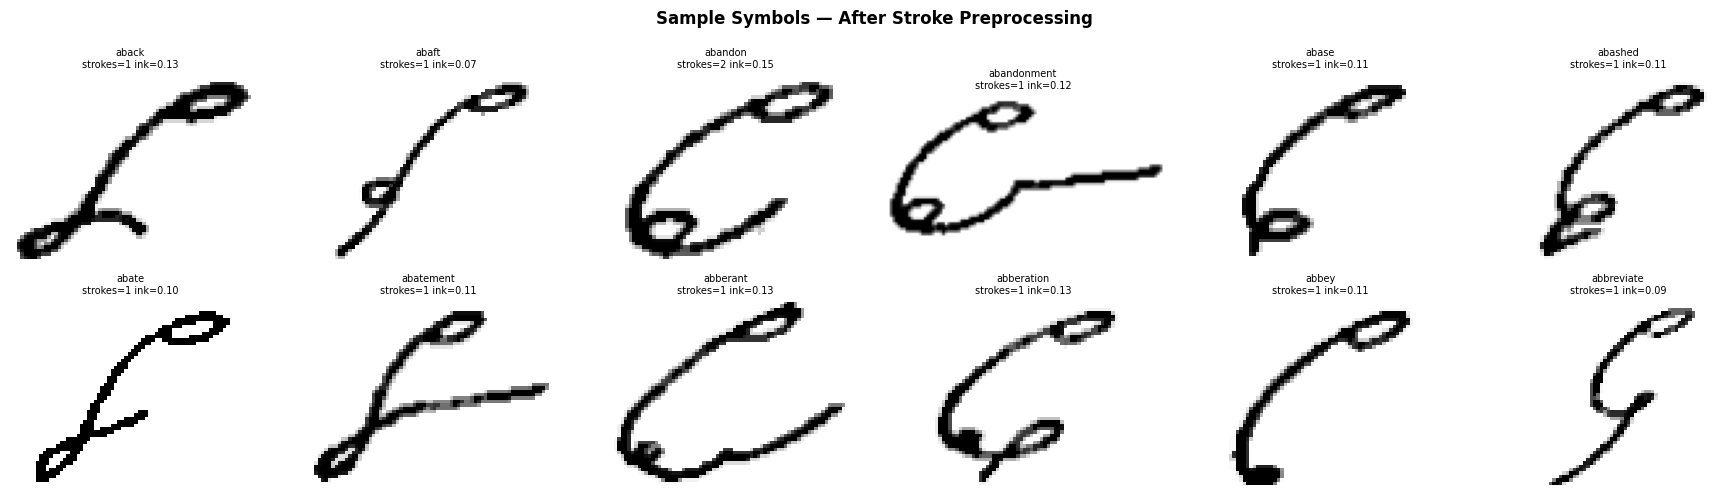

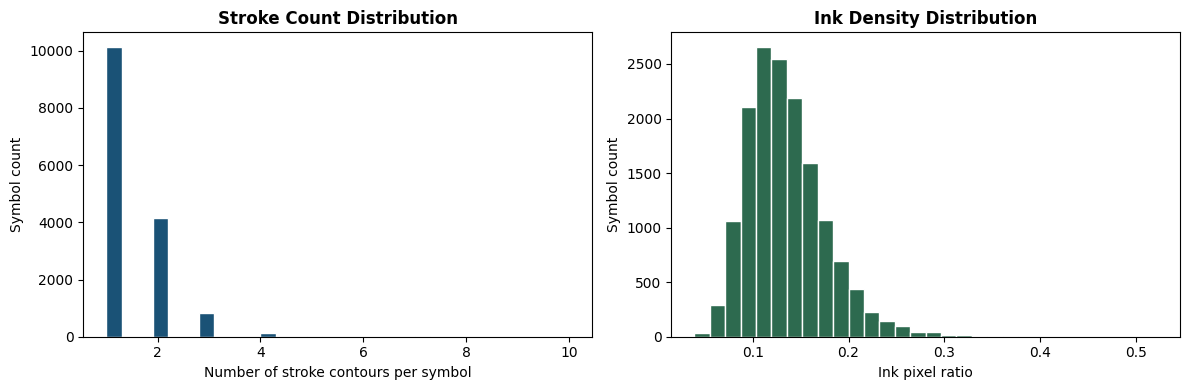

In [ ]:
# ---- Visualise stroke diagnostics for a sample of symbols ----
sample_words = list(symbol_images.keys())[:12]
fig, axes = plt.subplots(2, 6, figsize=(18, 5))
axes = axes.flatten()

for ax, word in zip(axes, sample_words):
    info = stroke_report[word]
    img  = symbol_images[word]
    ax.imshow(255 - img, cmap='gray', vmin=0, vmax=255)   # invert for display
    ax.set_title(
        f'{word}\nstrokes={info["num_strokes"]} ink={info["ink_ratio"]:.2f}',
        fontsize=7
    )
    ax.axis('off')

plt.suptitle('Sample Symbols — After Stroke Preprocessing', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ---- Stroke count distribution ----
stroke_counts = [stroke_report[w]['num_strokes'] for w in symbol_images]
ink_ratios    = [stroke_report[w]['ink_ratio']   for w in symbol_images]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(stroke_counts, bins=30, color='#1a5276', edgecolor='white')
axes[0].set_xlabel('Number of stroke contours per symbol')
axes[0].set_ylabel('Symbol count')
axes[0].set_title('Stroke Count Distribution', fontweight='bold')

axes[1].hist(ink_ratios, bins=30, color='#2d6a4f', edgecolor='white')
axes[1].set_xlabel('Ink pixel ratio')
axes[1].set_ylabel('Symbol count')
axes[1].set_title('Ink Density Distribution', fontweight='bold')

plt.tight_layout()
plt.show()

---
## Step 3: Define 15 Legal Principles — 5 Sentences Each (Paragraphs)

In [ ]:
# Each key   = legal principle (category / paragraph title)
# Each value = list of 5 judge sentences forming the paragraph
# All 5 sentences will be stitched as stacked rows into ONE paragraph image

PARAGRAPHS = {
    "Justice Must Be Fair": [
        "The court must ensure that justice is delivered fairly to every person",
        "No individual should be punished without proper evidence",
        "The law treats everyone equally regardless of status",
        "Courts must carefully examine the facts before making a decision",
        "Justice must not only be done but must also appear to be done",
    ],
    "Evidence Is the Foundation": [
        "A court cannot rely on assumptions or guesses",
        "Every decision must be based on credible and reliable evidence",
        "Witness statements documents and records must be examined carefully",
        "If evidence is weak or doubtful the benefit goes to the accused",
        "The court must always follow the rule of proof beyond reasonable doubt",
    ],
    "Presumption of Innocence": [
        "Every accused person is presumed innocent until proven guilty",
        "This principle protects individuals from wrongful punishment",
        "The burden of proof lies on the prosecution",
        "If the prosecution fails to establish guilt the accused must be acquitted",
        "The court must ensure that innocent persons are not convicted",
    ],
    "Law Is Above Everyone": [
        "In a democratic country the rule of law prevails",
        "No person including powerful individuals is above the law",
        "Courts must ensure that laws are applied equally to all citizens",
        "Any misuse of power must be checked by judicial authority",
        "This principle maintains public confidence in the justice system",
    ],
    "Right to Fair Trial": [
        "Every accused person has the right to a fair trial",
        "They must be given the opportunity to present their defense",
        "Courts must ensure transparency and impartiality",
        "A fair hearing protects the dignity of the legal process",
        "Justice cannot exist without fairness in procedure",
    ],
    "Natural Justice": [
        "The principles of natural justice require fairness in decision making",
        "No person should be judged without being heard",
        "Both sides must be given equal opportunity to present their case",
        "Bias or prejudice must not influence judicial decisions",
        "Courts must act impartially and objectively",
    ],
    "Protection of Fundamental Rights": [
        "The Constitution guarantees fundamental rights to every citizen",
        "Courts act as guardians of these rights",
        "Any violation of these rights must be examined seriously",
        "Judicial intervention is necessary to protect liberty and equality",
        "The Constitution remains the supreme law of the land",
    ],
    "Benefit of Doubt": [
        "If there is reasonable doubt in the prosecution case the accused must benefit",
        "Criminal conviction requires strong and convincing evidence",
        "Suspicion alone cannot replace proof",
        "Courts must be cautious before declaring someone guilty",
        "The rule ensures protection against wrongful conviction",
    ],
    "Judicial Responsibility": [
        "Judges carry a great responsibility in society",
        "Their decisions affect the lives and rights of people",
        "Every judgment must be reasoned and based on law",
        "Personal opinions must never influence judicial decisions",
        "Integrity and independence are essential for the judiciary",
    ],
    "Delay in Justice": [
        "Justice delayed can harm the faith of citizens in the legal system",
        "Courts must try to resolve disputes without unnecessary delay",
        "However speed must not compromise fairness",
        "Proper examination of facts and law is essential",
        "Timely justice strengthens the rule of law",
    ],
    "Equality Before Law": [
        "The Constitution guarantees equality before the law",
        "Courts must ensure that discrimination does not occur",
        "All individuals are treated equally in legal proceedings",
        "The justice system must remain neutral and unbiased",
        "Equality forms the foundation of democratic governance",
    ],
    "Judicial Review": [
        "Courts have the power to review actions of the government",
        "If any law violates the Constitution it can be declared invalid",
        "This power maintains the balance between branches of government",
        "Judicial review protects citizens from misuse of authority",
        "It ensures that constitutional principles are preserved",
    ],
    "Public Interest and Justice": [
        "Courts must consider the larger public interest while deciding cases",
        "Judgments should promote fairness and social welfare",
        "The legal system must protect vulnerable sections of society",
        "Law should serve the people and uphold justice",
        "Public confidence depends on fair and transparent decisions",
    ],
    "Accountability of Authorities": [
        "Government authorities must act within the limits of law",
        "Abuse of power cannot be tolerated in a constitutional democracy",
        "Courts can question administrative actions when necessary",
        "Accountability ensures transparency in governance",
        "This strengthens democratic institutions",
    ],
    "Importance of Truth": [
        "The purpose of a trial is to discover the truth",
        "Courts must carefully analyze evidence and testimonies",
        "False statements or fabricated evidence weaken justice",
        "Witnesses must speak truthfully under oath",
        "Truth remains the ultimate foundation of justice",
    ],
}

total_sentences = sum(len(v) for v in PARAGRAPHS.values())
print(f'Paragraphs (principles) : {len(PARAGRAPHS)}')
print(f'Sentences per paragraph : 5')
print(f'Total sentences         : {total_sentences}')
print(f'Total paragraph images  : {len(PARAGRAPHS)}  (1 stacked image per principle)')
print()
for i, (cat, sents) in enumerate(PARAGRAPHS.items(), 1):
    print(f'  {i:02d}. {cat}')
    for j, s in enumerate(sents, 1):
        print(f'       S{j}: {s}')
    print()

Paragraphs (principles) : 15
Sentences per paragraph : 5
Total sentences         : 75
Total paragraph images  : 15  (1 stacked image per principle)

  01. Justice Must Be Fair
       S1: The court must ensure that justice is delivered fairly to every person
       S2: No individual should be punished without proper evidence
       S3: The law treats everyone equally regardless of status
       S4: Courts must carefully examine the facts before making a decision
       S5: Justice must not only be done but must also appear to be done

  02. Evidence Is the Foundation
       S1: A court cannot rely on assumptions or guesses
       S2: Every decision must be based on credible and reliable evidence
       S3: Witness statements documents and records must be examined carefully
       S4: If evidence is weak or doubtful the benefit goes to the accused
       S5: The court must always follow the rule of proof beyond reasonable doubt

  03. Presumption of Innocence
       S1: Every accused per

---
## Step 4: Word Stemming & Coverage Check

In [ ]:
# ===== WORD STEMMING: Map sentence word forms to dataset base words =====

WORD_STEM_MAP = {
    # ---------- -es / -s verb forms ----------
    'approaches': 'approach', 'challenges': 'challenge', 'appears': 'appear',
    'seeks': 'seek', 'denies': 'deny', 'states': 'state', 'submits': 'submit',
    'prays': 'pray', 'reserves': 'reserve', 'undertakes': 'undertake',
    'discloses': 'disclose', 'violates': 'violate', 'exceeds': 'exceed',
    'invokes': 'invoke', 'pleads': 'plead', 'presents': 'present',
    'stands': 'stand', 'directs': 'direct', 'appreciates': 'appreciate',
    'argues': 'argue', 'contends': 'contend', 'relies': 'rely',
    'opposes': 'oppose', 'distinguishes': 'distinguish', 'applies': 'apply',
    'deposes': 'depose', 'verifies': 'verify', 'affirms': 'affirm',
    'draws': 'draw', 'craves': 'crave', 'begs': 'beg',
    'treats': 'treat', 'prevails': 'prevail', 'maintains': 'maintain',
    'protects': 'protect', 'requires': 'require', 'ensures': 'ensure',
    'carries': 'carry', 'affects': 'affect', 'remains': 'remain',
    'forms': 'form', 'strengthens': 'strengthen', 'weakens': 'weaken',
    'promotes': 'promote', 'serves': 'serve', 'depends': 'depend',
    'questions': 'question', 'tolerates': 'tolerate', 'preserves': 'preserve',
    'exists': 'exist', 'replaces': 'replace', 'lies': 'lie',
    'harms': 'harm', 'guarantees': 'guarantee', 'considers': 'consider',
    'declares': 'declare', 'decides': 'decide', 'protects': 'protect',

    # ---------- -ed past tense ----------
    'directed': 'direct', 'filed': 'file', 'issued': 'issue',
    'adjourned': 'adjourn', 'listed': 'list', 'posted': 'post',
    'pronounced': 'pronounce', 'passed': 'pass', 'modified': 'modify',
    'permitted': 'permit', 'reserved': 'reserve', 'concluded': 'conclude',
    'disposed': 'dispose', 'recorded': 'record', 'declared': 'declare',
    'admitted': 'admit', 'exhibited': 'exhibit', 'proved': 'prove',
    'examined': 'examine', 'recalled': 'recall', 'convicted': 'convict',
    'sentenced': 'sentence', 'released': 'release', 'remanded': 'remand',
    'acquitted': 'acquit', 'charged': 'charge', 'produced': 'produce',
    'committed': 'commit', 'referred': 'refer', 'dismissed': 'dismiss',
    'granted': 'grant', 'rejected': 'reject', 'quashed': 'quash',
    'allowed': 'allow', 'imposed': 'impose', 'supported': 'support',
    'fulfilled': 'fulfil', 'exhausted': 'exhaust', 'executed': 'execute',
    'stated': 'state', 'concealed': 'conceal', 'settled': 'settle',
    'argued': 'argue', 'submitted': 'submit', 'violated': 'violate',
    'suffered': 'suffer', 'acted': 'act', 'called': 'call',
    'placed': 'place', 'noted': 'note', 'marked': 'mark',
    'taken': 'take', 'heard': 'hear', 'sworn': 'swear',
    'made': 'make', 'brought': 'bring', 'given': 'give',
    'followed': 'follow', 'threatened': 'threaten', 'upheld': 'uphold',
    'exceeded': 'exceed', 'failed': 'fail', 'appointed': 'appoint',
    'certified': 'certify', 'pleased': 'please', 'furnished': 'furnish',
    'cured': 'cure', 'entitled': 'entitle', 'closed': 'close',
    'delivered': 'deliver', 'punished': 'punish', 'based': 'base',
    'applied': 'apply', 'checked': 'check', 'influenced': 'influence',
    'fabricated': 'fabricate', 'rendered': 'render', 'protected': 'protect',
    'required': 'require', 'ensured': 'ensure', 'maintained': 'maintain',
    'treated': 'treat', 'reasoned': 'reason', 'analyzed': 'analyze',
    'established': 'establish', 'preserved': 'preserve',
    'strengthened': 'strengthen', 'weakened': 'weaken', 'presumed': 'presume',
    'delayed': 'delay', 'harmed': 'harm', 'decided': 'decide',
    'considered': 'consider', 'tolerated': 'tolerate',

    # ---------- -ing forms ----------
    'being': 'be', 'hearing': 'hear', 'following': 'follow',
    'quashing': 'quash', 'dying': 'die', 'making': 'make',
    'including': 'include', 'convincing': 'convince', 'declaring': 'declare',
    'deciding': 'decide',

    # ---------- Plural -> singular ----------
    'allegations': 'allegation', 'submissions': 'submission',
    'provisions': 'provision', 'directions': 'direction',
    'conditions': 'condition', 'principles': 'principle',
    'judgments': 'judgment', 'precedents': 'precedent',
    'arguments': 'argument', 'statements': 'statement',
    'contents': 'content', 'documents': 'document',
    'remedies': 'remedy', 'parties': 'party',
    'records': 'record', 'defects': 'defect',
    'charges': 'charge', 'orders': 'order',
    'costs': 'cost', 'facts': 'fact', 'terms': 'term',
    'sides': 'side', 'rights': 'right', 'merits': 'merit',
    'annexures': 'annexure', 'damages': 'damage',
    'individuals': 'individual', 'citizens': 'citizen',
    'persons': 'person', 'judges': 'judge',
    'decisions': 'decision', 'testimonies': 'testimony',
    'assumptions': 'assumption', 'guesses': 'guess',
    'witnesses': 'witness', 'lives': 'life',
    'opinions': 'opinion', 'institutions': 'institution',
    'branches': 'branch', 'actions': 'action',
    'proceedings': 'proceeding', 'disputes': 'dispute',
    'sections': 'section', 'powers': 'power',
    'cases': 'case', 'limits': 'limit', 'authorities': 'authority',
    'guardians': 'guardian', 'violations': 'violation',

    # ---------- Adjective / adverb / noun forms ----------
    'equally': 'equal', 'carefully': 'careful',
    'fairly': 'fair', 'properly': 'proper',
    'credible': 'credit', 'reliable': 'rely',
    'wrongful': 'wrong', 'powerful': 'power',
    'judicial': 'judge', 'democratic': 'democracy',
    'constitutional': 'constitution', 'impartially': 'impartial',
    'objectively': 'objective', 'innocence': 'innocent',
    'ultimately': 'ultimate', 'necessary': 'necessity',
    'unnecessarily': 'unnecessary', 'transparent': 'transparency',
    'impartiality': 'impartial', 'neutrality': 'neutral',
    'unbiased': 'bias', 'misuse': 'use',
    'accountability': 'account', 'truthfully': 'truth',
    'reasonable': 'reason', 'convincing': 'convince',
    'cautious': 'caution', 'essential': 'essence',
    'larger': 'large', 'supreme': 'supreme',
    'invalid': 'valid', 'ultimate': 'ultimate',
    'guilty': 'guilt', 'innocent': 'innocence',
    'prosecution': 'prosecute', 'foundation': 'found',
    'vulnerable': 'vulnerability', 'timely': 'time',
    'seriously': 'serious', 'objectively': 'objective',
    'impartially': 'impartial',
}


def stem_word(word, symbol_images):
    """3-tier word matching:
    1. Exact match
    2. Manual stem map
    3. Auto suffix stripping (longest suffix first)
    """
    w = word.lower().strip()
    if w in symbol_images:
        return w
    if w in WORD_STEM_MAP and WORD_STEM_MAP[w] in symbol_images:
        return WORD_STEM_MAP[w]
    for suffix in ['ment', 'tion', 'ness', 'ing', 'ed', 'es', 'ly', 's']:
        if w.endswith(suffix) and len(w) > len(suffix) + 2:
            base = w[: -len(suffix)]
            if base in symbol_images:
                return base
    return None


# ---- Full coverage analysis across all 75 sentences ----
all_words = set()
for sents in PARAGRAPHS.values():
    for s in sents:
        clean = s.lower()
        for ch in '.,;:!?\'"()[]{}':
            clean = clean.replace(ch, '')
        all_words.update(clean.split())

found_direct  = 0
found_stemmed = 0
not_found     = []

for w in sorted(all_words):
    if w in symbol_images:
        found_direct += 1
    elif stem_word(w, symbol_images):
        found_stemmed += 1
    else:
        not_found.append(w)

total_found = found_direct + found_stemmed
print(f'Unique words across all 75 sentences : {len(all_words)}')
print(f'Direct match                         : {found_direct}')
print(f'Stemmed match                        : {found_stemmed}')
print(f'Total found                          : {total_found}/{len(all_words)} ({total_found/len(all_words)*100:.1f}%)')
print(f'\nMissing ({len(not_found)}): {", ".join(not_found) if not_found else "None"}')

Unique words across all 75 sentences : 280
Direct match                         : 161
Stemmed match                        : 66
Total found                          : 227/280 (81.1%)

Missing (53): a, accused, act, and, any, are, as, based, be, before, being, both, but, by, consider, done, ensure, ensures, equal, equality, equally, essential, establish, every, everyone, evidence, examination, examine, examined, exist, goes, governance, has, in, independence, is, judged, judgment, judgments, no, on, or, person, persons, proceedings, responsibility, right, rights, someone, status, transparency, treated, treats


---
## Step 5: Generate Paragraph Images

Each paragraph image is built as:
1. For every sentence → stitch its word symbols into **one horizontal row**
2. Stack all 5 sentence rows **vertically** with a line-gap between rows
3. Save the stacked image as one `.png` per principle

In [ ]:
LINE_GAP   = 20    # vertical gap in pixels between sentence rows
WORD_GAP   = (15, 30)  # horizontal gap between words (same as training)


def make_sentence_row(word_list, symbols_dict, target_h=TARGET_H, gap=WORD_GAP):
    """
    Stitch a list of words into one horizontal row image.
    Symbols are already preprocessed (stroke-analysed) — just place them.
    Returns: inverted grayscale image (white ink on black bg) or None.
    """
    parts = []
    for w in word_list:
        symbol = symbols_dict.get(w)
        if symbol is None:
            continue
        parts.append(symbol)   # already cleaned & normalised in Step 2

    if not parts:
        return None

    total_w = sum(p.shape[1] for p in parts) + (len(parts) - 1) * 22 + 20
    canvas  = np.zeros((target_h, total_w), dtype=np.uint8)
    xp = 10
    for p in parts:
        yo = 5 + random.randint(-3, 3)          # slight vertical jitter
        h, w = p.shape
        y1, y2 = max(0, yo), min(target_h, yo + h)
        x2     = min(total_w, xp + w)
        canvas[y1:y2, xp:x2] = cv2.bitwise_or(
            canvas[y1:y2, xp:x2], p[:y2 - y1, :x2 - xp]
        )
        xp += w + random.randint(*gap)

    return 255 - canvas      # invert: black ink on white background


def make_paragraph_img(sentence_rows, line_gap=LINE_GAP):
    """
    Stack multiple sentence row images vertically into one paragraph image.
    All rows are padded to the same width before stacking.

    Args:
        sentence_rows : list of 2D numpy images (one per sentence)
        line_gap      : vertical white space in px between rows

    Returns:
        paragraph image (H x W, uint8)
    """
    if not sentence_rows:
        return None

    # Pad all rows to the same width (widest row)
    max_w = max(r.shape[1] for r in sentence_rows)
    padded = []
    for row in sentence_rows:
        h, w = row.shape
        if w < max_w:
            pad = np.ones((h, max_w - w), dtype=np.uint8) * 255  # white padding
            row = np.hstack([row, pad])
        padded.append(row)

    # Create gap strip (white)
    gap_strip = np.ones((line_gap, max_w), dtype=np.uint8) * 255

    # Interleave rows with gap strips
    layers = []
    for i, row in enumerate(padded):
        layers.append(row)
        if i < len(padded) - 1:
            layers.append(gap_strip)

    return np.vstack(layers)


print(f'Paragraph stitcher ready')
print(f'  Sentence row height : {TARGET_H}px')
print(f'  Word gap            : {WORD_GAP[0]}–{WORD_GAP[1]}px')
print(f'  Line gap            : {LINE_GAP}px')

Paragraph stitcher ready
  Sentence row height : 64px
  Word gap            : 15–30px
  Line gap            : 20px


In [ ]:
# ===== Generate all 15 paragraph images =====
random.seed(42)

para_data         = []     # metadata for labels CSV
skipped_sentences = []     # sentences that produced no row image

for para_idx, (cat, sentences) in enumerate(PARAGRAPHS.items()):
    print(f'\n{"=" * 65}')
    print(f'{para_idx+1:02d}. {cat}')
    print(f'{"=" * 65}')

    sentence_rows    = []    # row images for this paragraph
    sentence_records = []    # per-sentence metadata

    for sent_idx, sent in enumerate(sentences):
        # --- Preprocessing ---
        clean = sent.lower()
        for ch in '.,;:!?\'"()[]{}':
            clean = clean.replace(ch, '')
        words = clean.split()

        # --- Stemming ---
        mapped_words       = []
        original_to_mapped = []
        for w in words:
            match = stem_word(w, symbol_images)
            if match:
                mapped_words.append(match)
                original_to_mapped.append(f'{w}->{match}' if w != match else w)
            else:
                original_to_mapped.append(f'{w}[SKIP]')

        coverage = round(len(mapped_words) / len(words) * 100, 1) if words else 0
        print(f'  S{sent_idx+1} ({len(mapped_words)}/{len(words)} | {coverage}%): {sent[:55]}')

        # --- Generate sentence row ---
        if len(mapped_words) >= 2:
            row_img = make_sentence_row(mapped_words, symbol_images)
        else:
            row_img = None

        if row_img is not None:
            sentence_rows.append(row_img)
            sentence_records.append({
                'sentence_index'   : sent_idx + 1,
                'original_sentence': sent,
                'words_used'       : '|'.join(mapped_words),
                'word_mapping'     : ' '.join(original_to_mapped),
                'words_total'      : len(words),
                'words_placed'     : len(mapped_words),
                'coverage'         : coverage,
                'row_height_px'    : row_img.shape[0],
                'row_width_px'     : row_img.shape[1],
            })
        else:
            skipped_sentences.append((cat, sent_idx + 1, sent))
            print(f'       -> SKIPPED (not enough matched words)')

    # --- Stack rows into paragraph image ---
    if not sentence_rows:
        print(f'  PARAGRAPH SKIPPED — no valid sentence rows')
        continue

    para_img = make_paragraph_img(sentence_rows)
    fname    = f'para_{para_idx:05d}.png'
    cv2.imwrite(f'output/paragraphs/images/{fname}', para_img)

    avg_cov = round(sum(r['coverage'] for r in sentence_records) / len(sentence_records), 1)
    print(f'  -> Saved {fname}  |  '
          f'size={para_img.shape[1]}x{para_img.shape[0]}px  |  '
          f'rows={len(sentence_rows)}/5  |  avg_cov={avg_cov}%')

    para_data.append({
        'filename'         : fname,
        'principle_index'  : para_idx + 1,
        'category'         : cat,
        'sentences_in_para': len(sentence_rows),
        'para_width_px'    : para_img.shape[1],
        'para_height_px'   : para_img.shape[0],
        'avg_coverage'     : avg_cov,
        'sentence_details' : json.dumps(sentence_records),  # full per-sentence info
    })


# ---- Save labels CSV ----
with open('output/paragraphs/labels.csv', 'w', newline='') as f:
    fields = ['filename', 'principle_index', 'category',
              'sentences_in_para', 'para_width_px', 'para_height_px',
              'avg_coverage', 'sentence_details']
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(para_data)

overall_avg = sum(d['avg_coverage'] for d in para_data) / len(para_data) if para_data else 0
print(f'\n{"=" * 65}')
print(f'FINAL RESULTS')
print(f'  Paragraph images generated : {len(para_data)}')
print(f'  Sentences skipped          : {len(skipped_sentences)}')
print(f'  Overall avg word coverage  : {overall_avg:.1f}%')
print(f'  Output                     : output/paragraphs/')


01. Justice Must Be Fair
  S1 (8/12 | 66.7%): The court must ensure that justice is delivered fairly 
  S2 (5/8 | 62.5%): No individual should be punished without proper evidenc
  S3 (4/8 | 50.0%): The law treats everyone equally regardless of status
  S4 (7/10 | 70.0%): Courts must carefully examine the facts before making a
  S5 (8/13 | 61.5%): Justice must not only be done but must also appear to b
  -> Saved para_00000.png  |  size=1133x400px  |  rows=5/5  |  avg_cov=62.1%

02. Evidence Is the Foundation
  S1 (5/8 | 62.5%): A court cannot rely on assumptions or guesses
  S2 (4/10 | 40.0%): Every decision must be based on credible and reliable e
  S3 (6/9 | 66.7%): Witness statements documents and records must be examin
  S4 (7/12 | 58.3%): If evidence is weak or doubtful the benefit goes to the
  S5 (12/12 | 100.0%): The court must always follow the rule of proof beyond r
  -> Saved para_00001.png  |  size=1694x400px  |  rows=5/5  |  avg_cov=65.5%

03. Presumption of Innocence
  S

---
## Step 6: Preview & Statistics

Total paragraph images : 15
Overall avg coverage   : 76.2%

 principle_index                         category  sentences_in_para  para_width_px  para_height_px  avg_coverage
               1             Justice Must Be Fair                  5           1133             400          62.1
               2       Evidence Is the Foundation                  5           1694             400          65.5
               3         Presumption of Innocence                  5           1389             400          77.6
               4            Law Is Above Everyone                  5           1214             400          75.2
               5              Right to Fair Trial                  5           1278             400          68.3
               6                  Natural Justice                  5           1277             400          70.9
               7 Protection of Fundamental Rights                  5           1608             400          70.9
               8            

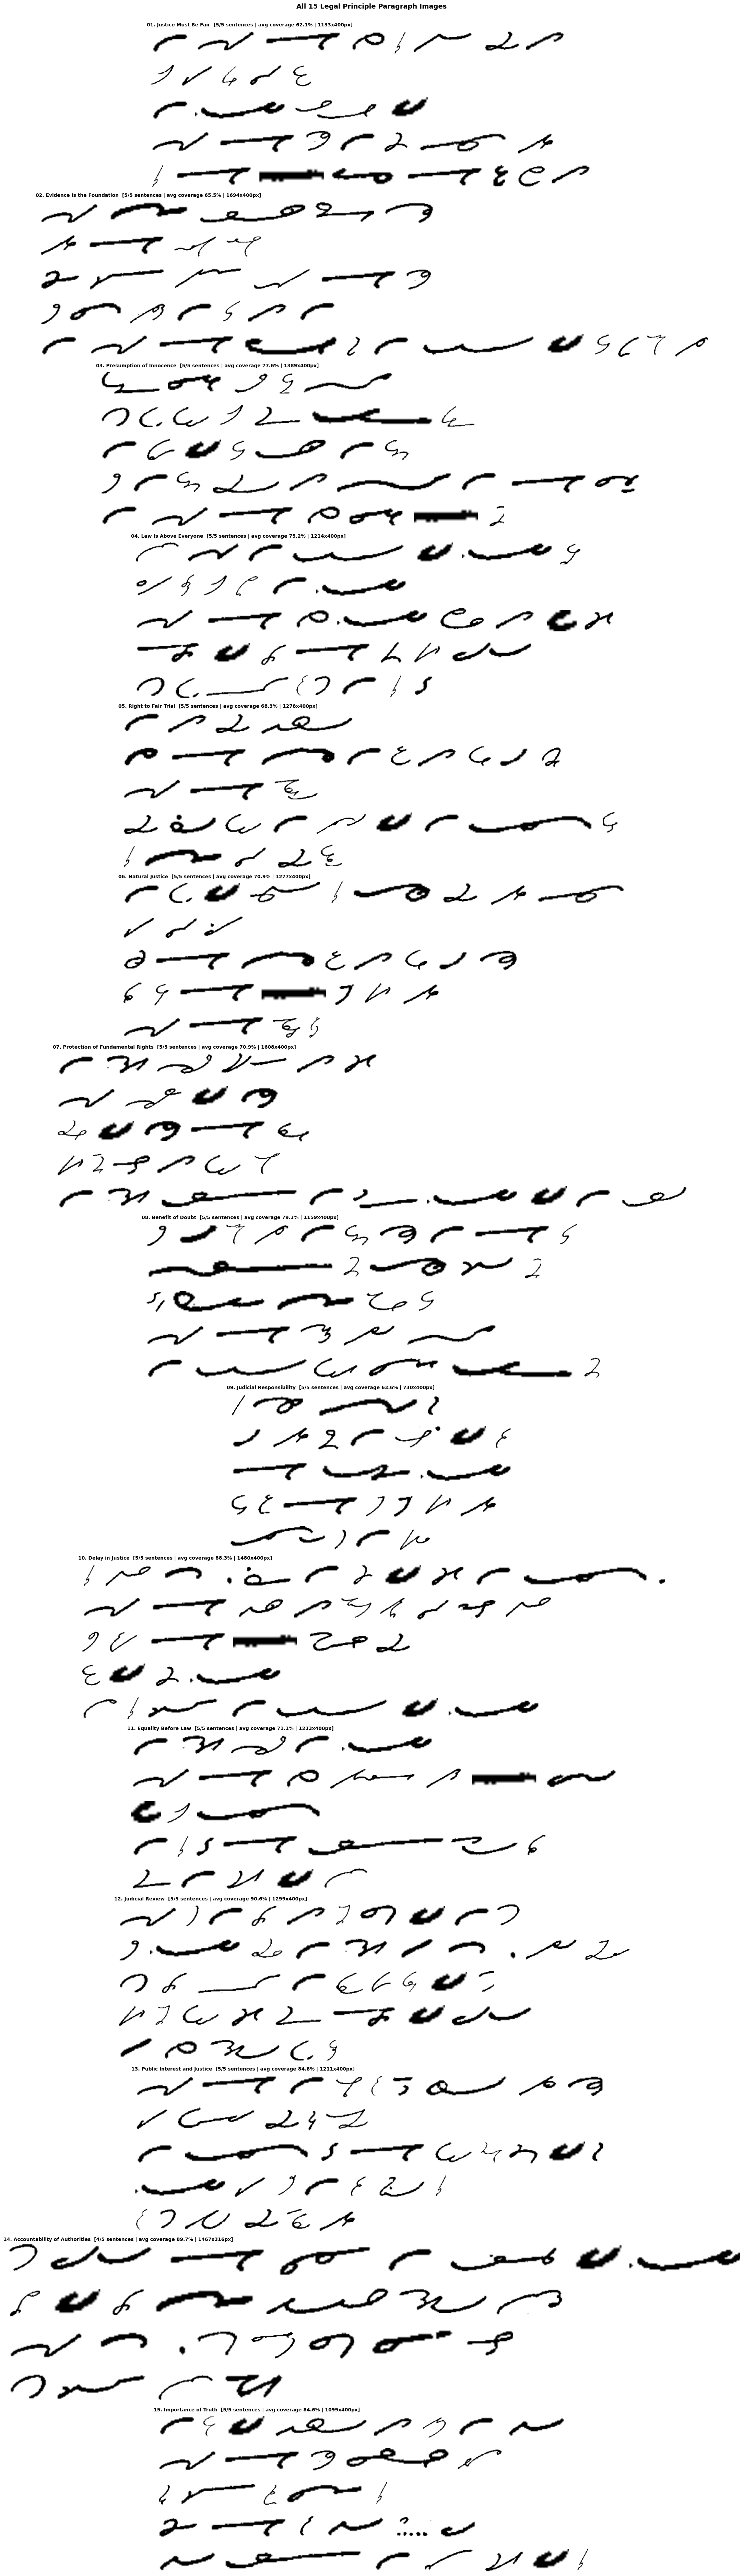

In [ ]:
import pandas as pd

df = pd.read_csv('output/paragraphs/labels.csv')
print(f'Total paragraph images : {len(df)}')
print(f'Overall avg coverage   : {df["avg_coverage"].mean():.1f}%')
print()
print(df[['principle_index', 'category', 'sentences_in_para',
          'para_width_px', 'para_height_px', 'avg_coverage']].to_string(index=False))

# ---- Show all 15 paragraph images ----
fig, axes = plt.subplots(len(df), 1, figsize=(22, 5 * len(df)))
if len(df) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, df.iterrows()):
    img = cv2.imread(
        f'output/paragraphs/images/{row["filename"]}',
        cv2.IMREAD_GRAYSCALE
    )
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(
        f'{row["principle_index"]:02d}. {row["category"]}  '
        f'[{row["sentences_in_para"]}/5 sentences | avg coverage {row["avg_coverage"]}% | '
        f'{row["para_width_px"]}x{row["para_height_px"]}px]',
        fontsize=10, loc='left', fontweight='bold'
    )
    ax.axis('off')

plt.suptitle('All 15 Legal Principle Paragraph Images', fontsize=14, fontweight='bold', y=1.001)
plt.tight_layout()
plt.show()

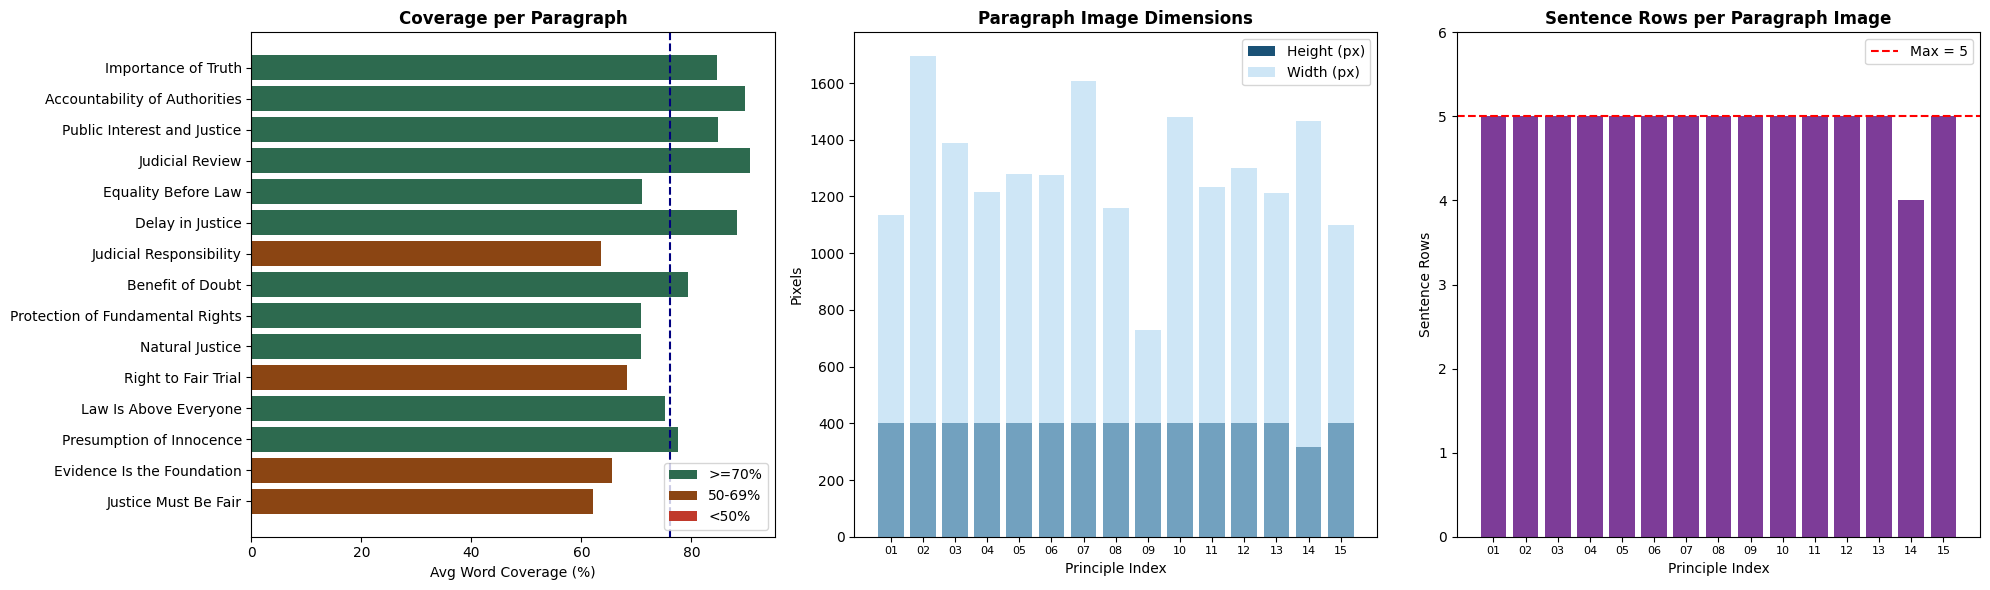

In [ ]:
# ---- Statistics charts ----
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Avg coverage per principle
from matplotlib.patches import Patch
colors = ['#2d6a4f' if c >= 70 else '#8b4513' if c >= 50 else '#c0392b'
          for c in df['avg_coverage']]
axes[0].barh(df['category'], df['avg_coverage'], color=colors)
axes[0].axvline(df['avg_coverage'].mean(), color='navy', linestyle='--',
                label=f'Mean: {df["avg_coverage"].mean():.0f}%')
axes[0].set_xlabel('Avg Word Coverage (%)')
axes[0].set_title('Coverage per Paragraph', fontweight='bold')
legend_elems = [
    Patch(facecolor='#2d6a4f', label='>=70%'),
    Patch(facecolor='#8b4513', label='50-69%'),
    Patch(facecolor='#c0392b', label='<50%'),
]
axes[0].legend(handles=legend_elems, loc='lower right')

# 2. Paragraph image dimensions
x = range(len(df))
axes[1].bar(x, df['para_height_px'], color='#1a5276', label='Height (px)')
axes[1].bar(x, df['para_width_px'],  color='#aed6f1', label='Width (px)',  alpha=0.6)
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{i+1:02d}" for i in range(len(df))], fontsize=8)
axes[1].set_xlabel('Principle Index')
axes[1].set_ylabel('Pixels')
axes[1].set_title('Paragraph Image Dimensions', fontweight='bold')
axes[1].legend()

# 3. Sentences placed per paragraph
axes[2].bar(x, df['sentences_in_para'], color='#7d3c98')
axes[2].axhline(5, color='red', linestyle='--', label='Max = 5')
axes[2].set_xticks(x)
axes[2].set_xticklabels([f"{i+1:02d}" for i in range(len(df))], fontsize=8)
axes[2].set_xlabel('Principle Index')
axes[2].set_ylabel('Sentence Rows')
axes[2].set_title('Sentence Rows per Paragraph Image', fontweight='bold')
axes[2].set_ylim(0, 6)
axes[2].legend()

plt.tight_layout()
plt.show()

---
## Step 7: Save to Google Drive

In [ ]:
from google.colab import drive
import shutil

drive.mount('/content/drive')

dest = '/content/drive/MyDrive/pitman_models/paragraph_dataset'
os.makedirs(dest, exist_ok=True)

for f in os.listdir('output/paragraphs/images'):
    shutil.copy(f'output/paragraphs/images/{f}', os.path.join(dest, f))
shutil.copy('output/paragraphs/labels.csv', os.path.join(dest, 'labels.csv'))

print(f'Saved {len(os.listdir(dest)) - 1} paragraph images + labels.csv to:')
print(f'  {dest}')

Mounted at /content/drive
Saved 15 paragraph images + labels.csv to:
  /content/drive/MyDrive/pitman_models/paragraph_dataset


In [ ]:
# Download as zip
shutil.make_archive('paragraph_dataset', 'zip', 'output/paragraphs')
files.download('paragraph_dataset.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Done!

### What was generated:
- **15 paragraph images** — one per legal principle
- Each paragraph = **5 sentence rows stacked vertically** with 20px line gap
- Full **stroke-level preprocessing** on every symbol before stitching:
  - Ink ratio gate (2%–90%)
  - Contour / stroke count gate (1–40 strokes)
  - Tight bounding-box crop with 2px padding
  - Height normalisation to 54px
  - Morphological open to remove noise specks

### `labels.csv` columns:
| Column | Description |
|---|---|
| `filename` | `para_00000.png` … `para_00014.png` |
| `principle_index` | 1–15 |
| `category` | Legal principle name |
| `sentences_in_para` | How many rows are in the image (max 5) |
| `para_width_px` | Image width |
| `para_height_px` | Image height |
| `avg_coverage` | Average word coverage % across all sentences |
| `sentence_details` | JSON list — per-sentence mapping, coverage, row size |

### Stroke preprocessing summary:
| Gate | Threshold |
|---|---|
| Min ink ratio | 2% |
| Max ink ratio | 90% |
| Min stroke contours | 1 |
| Max stroke contours | 40 |
| Min symbol width | 5px |
| Post-clean ink check | ≥10 ink pixels |
